# Multinomial processing trees

When people recall a list of word pairs, do they fail to store a pair,
or fail to retrieve it? A multinomial processing tree separates the two
processes. The pair-clustering model of Lee & Wagenmakers (2013, chapter
14.1) estimates the probabilities of storage and retrieval from the
counts of four kinds of response. This case study takes the PyMC version
of the model and uses it in `elicito` with the PyMC adapter.

The case study has three parts:

1. **Translate.** One call turns the PyMC model into a TensorFlow model.
2. **Validate.** The two models give the same samples. The TensorFlow model
   is fast enough for an elicitation.
3. **Elicit.** Two simulated experts give their knowledge about the
   responses. `elicito` learns a prior from each expert. PyMC then fits the
   model with each prior.

**Main results**

- The two models give the same distributions: the largest KS distance is
  0.015.
- The translated model draws 10 000 samples more than 50 times faster
  than PyMC.
- The elicited quantiles agree with the quantiles of both experts.
- The 420 pairs dominate a prior that agrees with them. An expert who
  expects practised participants moves the retrieval $r$ from 0.26 to
  0.51, and the model then predicts the counts of trial 1 worse.

> **Note:** the adapter needs Python 3.12 or later and the optional
> dependency `pymc`. Install it with `pip install "elicito[pymc]"`.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
# mkdocs runs the notebook in the repository root; the data are next to it
if os.path.isdir("docs/case-studies"):
    os.chdir("docs/case-studies")

In [2]:
import time
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import tensorflow as tf
import tensorflow_probability as tfp
from scipy import stats

import elicito as el
from elicito.adapter import pymc as adapter_pymc

tfd = tfp.distributions

SEED = tf.constant([2013, 14], dtype=tf.int32)
DRAWS = 10_000
TOL = 0.05  # largest KS distance D that shows agreement

In [3]:
import logging

# hide the INFO messages of pm.sample; the progress bar stays
logging.getLogger("pymc").setLevel(logging.WARNING)

# colours of the figures: one fixed colour for each entity
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.titlesize": "medium",
        "legend.frameon": False,
    }
)

## The pair-clustering task

Participants study a list of word pairs that are related in meaning, for
example "dog" and "cat". Later, they recall as many words as they can, in
any order. Each pair falls into one of four categories:

1. both words are recalled one after the other,
2. both words are recalled, but not one after the other,
3. one word is recalled,
4. no word is recalled.

The task has six trials of study and recall. The data are the counts of
420 pairs in trials 1, 2 and 6. This case study fits the model to trial
1.

In [4]:
kall = np.array([[45, 24, 97, 254], [106, 41, 107, 166], [243, 64, 65, 48]])
TRIALS = (1, 2, 6)
k = kall[0]  # trial 1
n = int(k.sum())  # pairs
CATEGORIES = ("together", "apart", "one word", "none")

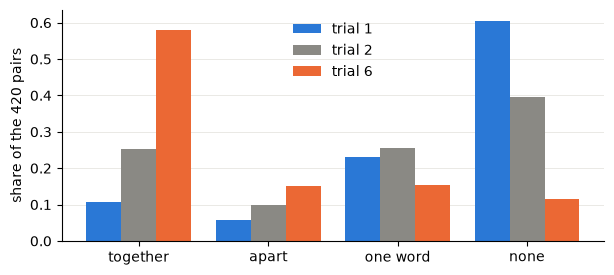

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
x_pos = np.arange(4)
for offset, (trial, counts), color in zip(
    (-0.27, 0.0, 0.27), zip(TRIALS, kall), (BLUE, GREY, ORANGE)
):
    ax.bar(
        x_pos + offset,
        counts / counts.sum(),
        width=0.27,
        color=color,
        label=f"trial {trial}",
    )
ax.set(
    xticks=x_pos,
    xticklabels=CATEGORIES,
    ylabel="share of the 420 pairs",
)
ax.grid(axis="x", visible=False)
ax.legend()
plt.show()

With practice, the participants recall more pairs together: the share of
category 1 grows from 0.11 in trial 1 to 0.58 in trial 6. The share of
category 4 falls from 0.60 to 0.11.

## The model

The tree has three parameters:

- $c$, the probability to **store** a pair as a cluster,
- $r$, the probability to **retrieve** a stored cluster,
- $u$, the probability to recall a single word that is not in a cluster.

A stored and retrieved cluster gives category 1. A pair that is not
stored gives categories 2 to 4, by the recall of each word on its own.
The probabilities of the four categories are

$$\begin{aligned}
\theta_1 &= c r, &
\theta_2 &= (1 - c) u^2, \\
\theta_3 &= 2 u (1 - c)(1 - u), &
\theta_4 &= c (1 - r) + (1 - c)(1 - u)^2,
\end{aligned}$$

and the counts are $k \sim \operatorname{Multinomial}(\theta, 420)$. The
book gives $c$, $r$ and $u$ a $\operatorname{Beta}(1, 1)$ prior.

The PyMC model follows the rules of [Use a PyMC model][use-a-pymc-model]:
each input of a prior is a named `pm.Data` node.

In [6]:
PARAMETERS = ("c", "r", "u")
BOOK_PRIOR = {f"{name}_{arg}": 1.0 for name in PARAMETERS for arg in ("a", "b")}


def beta_prior(name: str) -> Any:
    """Add a Beta(1, 1) prior with pm.Data inputs to the model"""
    return pm.Beta(
        name, alpha=pm.Data(f"{name}_a", 1.0), beta=pm.Data(f"{name}_b", 1.0)
    )


with pm.Model() as model:
    c, r, u = (beta_prior(name) for name in PARAMETERS)
    theta = pm.math.stack(
        [
            c * r,
            (1 - c) * u**2,
            2 * u * (1 - c) * (1 - u),
            c * (1 - r) + (1 - c) * (1 - u) ** 2,
        ]
    )
    pm.Multinomial("kobs", p=theta, n=n, observed=k)

## From PyMC to TensorFlow

`adapter_pymc.parameters` lists the priors that `elicito` reads.
`adapter_pymc.model` returns the translated model. It returns each
observed variable and each `pm.Deterministic` by name: here `kobs`.

In [7]:
print([(p["name"], p["family"].__name__) for p in adapter_pymc.parameters(model)])

generative_model = adapter_pymc.model(model)()

[('c', 'Beta'), ('r', 'Beta'), ('u', 'Beta')]


## Do the two models agree?

Both models get the same priors. The TensorFlow model and `pm.draw` each
draw 10 000 samples. If the translation is correct, the two samples come
from the same distribution.

The Kolmogorov-Smirnov (KS) distance $D$ measures the largest difference
between the two cumulative distributions. With 10 000 draws, a value
below 0.05 shows agreement. The table shows the largest $D$ of the four
categories.

In [8]:
def sample_priors(pymc_model: Any, draws: int, seed: Any) -> Any:
    """Sample the priors of a PyMC model in TensorFlow, shape (1, draws, P)"""
    parameters = adapter_pymc.parameters(pymc_model)
    seeds = tfp.random.split_seed(seed, n=len(parameters))
    columns = []
    for parameter, param_seed in zip(parameters, seeds):
        args = {
            arg: float(pymc_model[hyper["name"]].get_value())
            for arg, hyper in parameter["hyperparams"].items()
        }
        columns.append(parameter["family"](**args).sample(draws, seed=param_seed))
    return tf.stack(columns, axis=-1)[None]


seed_priors, seed_model = tfp.random.split_seed(SEED)
prior_samples = sample_priors(model, DRAWS, seed_priors)
tf_out = generative_model(prior_samples, seed=seed_model)
pm_out = pm.draw(model["kobs"], draws=DRAWS, random_seed=1)

samples = {
    "TensorFlow": np.asarray(tf_out["kobs"][0], dtype=float).reshape(DRAWS, -1),
    "PyMC": np.asarray(pm_out, dtype=float).reshape(DRAWS, -1),
}
distances = [
    stats.ks_2samp(
        samples["TensorFlow"][:, j], samples["PyMC"][:, j], method="asymp"
    ).statistic
    for j in range(4)
]

print(f"{'category':<10}{'TensorFlow mean, sd':>22}{'PyMC mean, sd':>18}{'D':>8}")
for j, name in enumerate(CATEGORIES):
    tf_stats, pm_stats = (
        f"{values[:, j].mean():.1f}, {values[:, j].std():.1f}"
        for values in samples.values()
    )
    print(f"{name:<10}{tf_stats:>22}{pm_stats:>18}{distances[j]:>8.3f}")
assert max(distances) < TOL

category     TensorFlow mean, sd     PyMC mean, sd       D
together             105.2, 93.1       103.9, 92.8   0.010
apart                 68.8, 82.6        70.5, 83.8   0.012
one word              69.8, 54.7        70.6, 54.6   0.015
none                176.2, 103.5      175.0, 103.3   0.010


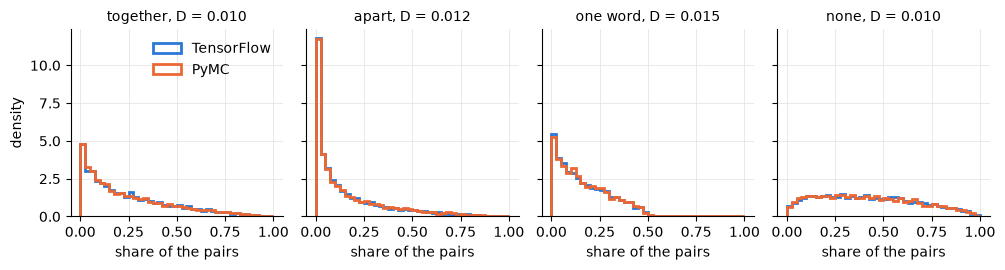

In [9]:
fig, axs = plt.subplots(1, 4, figsize=(10, 2.8), sharey=True)
bins = np.linspace(0, 1, 41)
for j, ax in enumerate(axs):
    for (label, values), color in zip(samples.items(), (BLUE, ORANGE)):
        ax.hist(
            values[:, j] / n,
            bins,
            density=True,
            histtype="step",
            lw=2,
            color=color,
            label=label,
        )
    ax.set(
        xlabel="share of the pairs", title=f"{CATEGORIES[j]}, D = {distances[j]:.3f}"
    )
axs[0].set_ylabel("density")
axs[0].legend()
fig.tight_layout()
plt.show()

The distributions of the two models overlap. Under the book prior,
category 2 has the most shares near 0, and category 4 has the widest
spread.

## How fast is the translated model?

During the elicitation, `elicito` runs the model at each step of the
search. A fast model is therefore important. We time one forward pass of
10 000 samples. Each model runs once before the timing, so the time does
not include the compilation.

PyMC draws one sample per call of its compiled function. The TensorFlow
model draws all samples in one call.

In [10]:
REPEATS = 5

draw_pymc = pm.compile([], [model["kobs"]], random_seed=1)


def run_pymc() -> None:
    """Draw DRAWS samples with the compiled PyMC function"""
    for _ in range(DRAWS):
        draw_pymc()


def run_tensorflow() -> None:
    """Draw DRAWS samples with the translated model"""
    out = generative_model(prior_samples, seed=seed_model)
    _ = [value.numpy() for value in out.values()]


seconds = {}
for label, run in (("TensorFlow", run_tensorflow), ("PyMC", run_pymc)):
    run()  # warm-up
    times = []
    for _ in range(REPEATS):
        start = time.perf_counter()
        run()
        times.append(time.perf_counter() - start)
    seconds[label] = float(np.median(times))

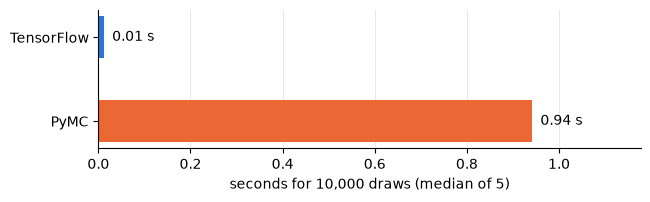

In [11]:
fig, ax = plt.subplots(figsize=(7, 1.8))
labels = list(seconds)
ax.barh(labels, list(seconds.values()), color=[BLUE, ORANGE], height=0.5)
for i, value in enumerate(seconds.values()):
    ax.text(value, i, f"  {value:.2f} s", va="center")
ax.set(
    xlabel=f"seconds for {DRAWS:,} draws (median of {REPEATS})",
    xlim=(0, 1.25 * max(seconds.values())),
)
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.show()

The translated model is more than 50 times faster. The exact times depend
on the computer and its load.

## Two simulated experts

A simulated expert answers with the quantiles that a chosen prior gives.
A real expert gives these quantiles directly.

| Expert | $c$ | $r$ | $u$ | Description |
| :-- | :-- | :-- | :-- | :-- |
| A | Uniform(0.35, 0.6) | Uniform(0.1, 0.35) | Uniform(0.2, 0.45) | first trial |
| B | Uniform(0.55, 0.75) | Uniform(0.75, 0.95) | Uniform(0.55, 0.75) | practised |

Expert A expects the behaviour of a first trial. Expert B expects the
behaviour of practised participants, as in trial 6.

Each expert gives quantiles of the share of each of the four categories,
for one trial of 420 pairs:

- **together:** "Of 100 word pairs, how many are recalled with both words one after
  the other?"
- **apart:** "Of 100 word pairs, how many are recalled with both words, but apart?"
- **one word:** "Of 100 word pairs, how many are recalled with one word only?"
- **none:** "Of 100 word pairs, how many are not recalled at all?"

The expert answers each question with the 10 %, 25 %, 50 %, 75 % and
90 % quantiles. For the 10 % quantile, the question is: "Give a value
that is too low with a probability of 10 %."

The four shares sum to 1, so they hold three independent quantities: as
many as the model has parameters.

In [12]:
EXPERTS = {
    "Expert A": {
        "c": tfd.Uniform(0.35, 0.6),
        "r": tfd.Uniform(0.1, 0.35),
        "u": tfd.Uniform(0.2, 0.45),
    },
    "Expert B": {
        "c": tfd.Uniform(0.55, 0.75),
        "r": tfd.Uniform(0.75, 0.95),
        "u": tfd.Uniform(0.55, 0.75),
    },
}


def category_share(j: int) -> Any:
    """Return a target function for the share of category j"""

    def share(kobs: Any) -> Any:
        return tf.cast(kobs[..., j], tf.float32) / n

    return share


PROBS = (0.1, 0.25, 0.5, 0.75, 0.9)
targets = [
    el.quantiles(name, output=category_share(j), probs=PROBS)
    for j, name in enumerate(CATEGORIES)
]

In [13]:
fits = {}
for expert, ground_truth in EXPERTS.items():
    eliobj = el.Elicit(model, targets, seeds=(1, 2, 3), epochs=400, verbose=False)
    fits[expert] = eliobj.fit(
        el.expert.simulator(ground_truth=ground_truth, num_samples=10_000)
    )

## Did the elicitation succeed?

The loss must go down and level off. The elicited quantiles must be near
the quantiles of the expert: this is the check of the elicitation.

Different priors can give the same quantiles. The learned prior can
therefore differ from the prior of the simulated expert, and the
elicitation is still correct.

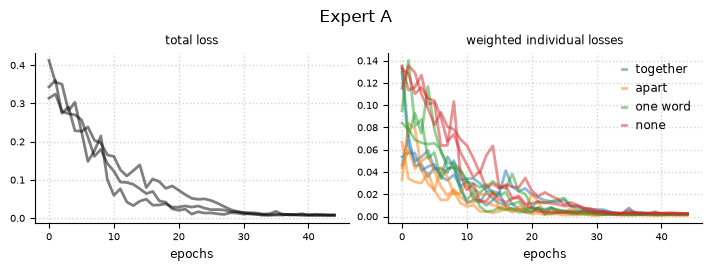

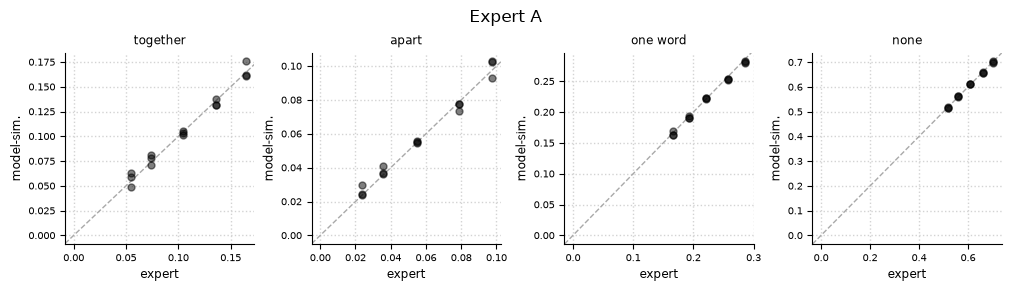

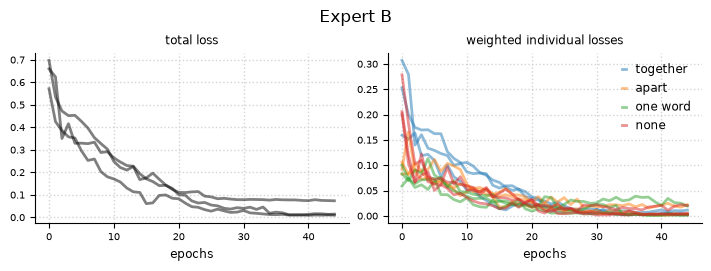

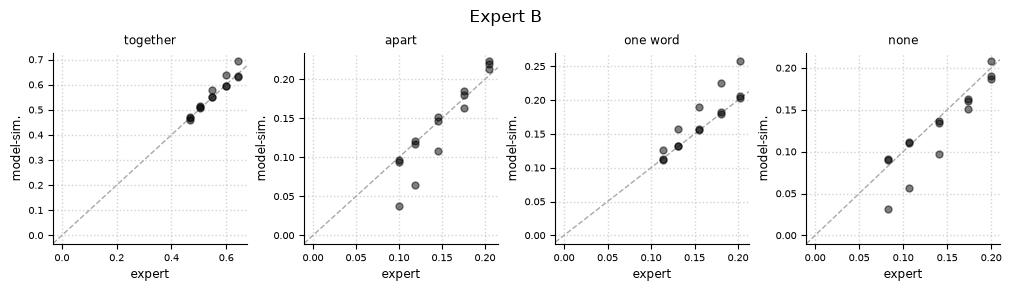

In [14]:
for expert, fit in fits.items():
    fig, _ = fit.plot.loss(figsize=(7, 2.6))
    fig.suptitle(expert)
    plt.show()
    fig, _ = fit.plot.elicits(cols=4, figsize=(10, 2.8))
    fig.suptitle(expert)
    plt.show()

## From prior to posterior

We now give each elicited prior back to the PyMC model with
`pm.set_data`. PyMC then fits the model to the counts of trial 1. The
book prior, $\operatorname{Beta}(1, 1)$, is the reference. We use the
replication with the lowest loss.

In [15]:
PRIORS = {"Book": BOOK_PRIOR}
PRIORS |= {expert: fit.hyperparameters() for expert, fit in fits.items()}

for label, prior in PRIORS.items():
    print(f"{label:<10}" + "  ".join(f"{k} {v:.2f}" for k, v in prior.items()))

Book      c_a 1.00  c_b 1.00  r_a 1.00  r_b 1.00  u_a 1.00  u_b 1.00
Expert A  c_b 23.58  r_b 25.89  u_b 21.54  c_a 21.95  r_a 7.43  u_a 10.60
Expert B  c_b 20.25  r_b 8.45  u_b 13.51  c_a 36.60  r_a 50.37  u_a 24.71


In [16]:
posteriors, predictives = {}, {}
for label, prior in PRIORS.items():
    with model:
        pm.set_data(prior)
        idata = pm.sample(1000, tune=1000, chains=4, random_seed=1, progressbar=True)
        pm.sample_posterior_predictive(
            idata, extend_inferencedata=True, random_seed=1, progressbar=False
        )
    posteriors[label] = idata.posterior
    predictives[label] = idata.posterior_predictive

print(f"{'prior':<10}{'parameter':<10}{'mean':>6}{'90 % interval':>16}")
for label, posterior in posteriors.items():
    for name in PARAMETERS:
        values = posterior[name].values.ravel()
        low, high = np.quantile(values, [0.05, 0.95])
        print(
            f"{label:<10}{name:<10}{values.mean():>6.2f}{f'{low:.2f}, {high:.2f}':>16}"
        )

Output()

Output()

Output()

prior     parameter   mean   90 % interval
Book      c           0.45      0.28, 0.57
Book      r           0.26      0.17, 0.40
Book      u           0.32      0.23, 0.40
Expert A  c           0.48      0.40, 0.56
Expert A  r           0.23      0.17, 0.29
Expert A  u           0.33      0.28, 0.39
Expert B  c           0.36      0.24, 0.50
Expert B  r           0.51      0.36, 0.68
Expert B  u           0.28      0.23, 0.36


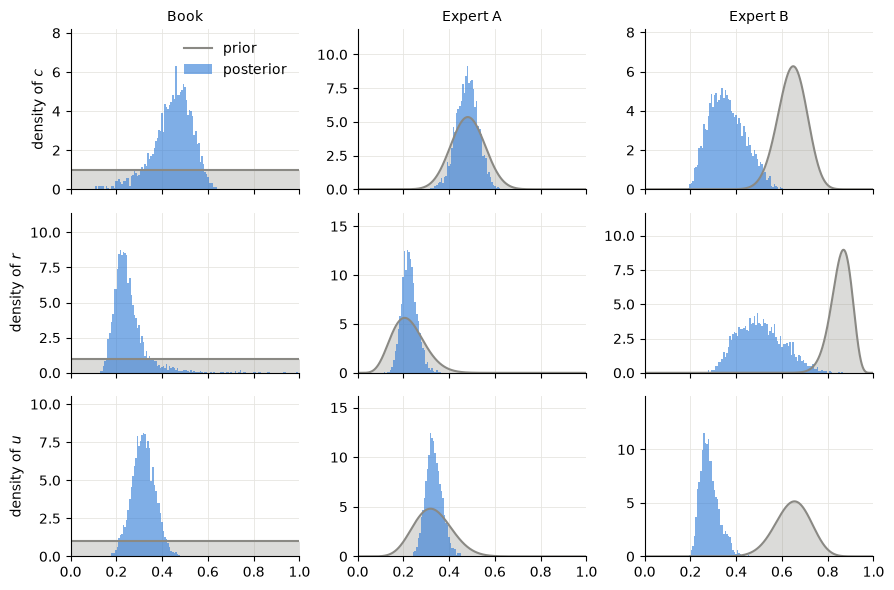

In [17]:
x_grid = np.linspace(0, 1, 1000)

fig, axs = plt.subplots(len(PARAMETERS), len(PRIORS), figsize=(9, 6), sharex=True)
for row, name in enumerate(PARAMETERS):
    for col, (label, prior) in enumerate(PRIORS.items()):
        ax = axs[row, col]
        density = stats.beta(prior[f"{name}_a"], prior[f"{name}_b"]).pdf(x_grid)
        ax.fill_between(x_grid, density, color=GREY, alpha=0.3, lw=0)
        ax.plot(x_grid, density, color=GREY, lw=1.5, label="prior")
        heights, *_ = ax.hist(
            posteriors[label][name].values.ravel(),
            bins=np.linspace(0, 1, 150),
            density=True,
            histtype="stepfilled",
            color=BLUE,
            alpha=0.6,
            label="posterior",
        )
        ax.set(xlim=(0, 1), ylim=(0, 1.3 * max(heights.max(), density.max())))
        if row == 0:
            ax.set_title(label)
        if col == 0:
            ax.set_ylabel(f"density of ${name}$")
axs[0, 0].legend()
fig.tight_layout()
plt.show()

- **Book prior and expert A.** The posterior means are almost the same:
  $c$ 0.45 and 0.48, $r$ 0.26 and 0.23, $u$ 0.32 and 0.33. The prior of
  expert A agrees with trial 1, and makes the 90 % intervals narrower:
  for $r$, 0.17 to 0.29 instead of 0.17 to 0.40.
- **Expert B.** The prior of $r$, Beta(50.37, 8.45), has the mean 0.86
  and counts like 59 observations. The posterior of $r$ moves from 0.26
  to 0.51. The model then explains the few category 1 responses with a
  smaller $c$: 0.36 instead of 0.45.

## Does the model fit the data?

A posterior predictive check simulates new data from the fitted model,
once for each posterior draw. The figure repeats the first figure, with
one panel for each prior.

The dots are the observed shares of trial 1. The bars and lines are the
median and the 90 % interval of the simulated shares.

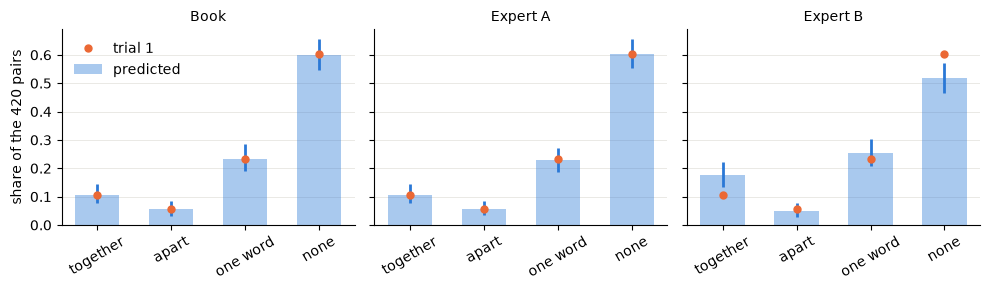

In [18]:
fig, axs = plt.subplots(1, len(PRIORS), figsize=(10, 3), sharey=True)
for ax, (label, predictive) in zip(axs, predictives.items()):
    shares = predictive["kobs"].values.reshape(-1, 4) / n
    low, mid, high = np.quantile(shares, [0.05, 0.5, 0.95], axis=0)
    ax.bar(x_pos, mid, color=BLUE, alpha=0.4, width=0.6, label="predicted")
    ax.vlines(x_pos, low, high, color=BLUE, lw=2)
    ax.plot(x_pos, k / n, "o", color=ORANGE, ms=5, label="trial 1")
    ax.set(title=label, xticks=x_pos, xticklabels=CATEGORIES)
    ax.tick_params(axis="x", labelrotation=30)
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel(f"share of the {n} pairs")
axs[0].legend()
fig.tight_layout()
plt.show()

With the book prior and with expert A, all four observed shares are
inside the 90 % intervals. With expert B, the model predicts too many
pairs in category 1 (median about 0.18, observed 0.11) and too few in
category 4 (about 0.52, observed 0.60). The prior of expert B does not
fit trial 1, and the posterior predictive check shows it.

## Takeaways

- **Translation.** One call translates the PyMC model. The largest KS
  distance of the four categories is 0.015.
- **Speed.** The translated model is more than 50 times faster than PyMC.
- **Elicitation.** The four shares hold three independent quantities, as
  many as the model has parameters. `elicito` learns a prior with the
  means of each expert.
- **Posterior predictive check.** A strong prior that disagrees with the
  data moves the posterior. The posterior predictive check shows if the
  model then still fits the data.

## Appendix

The PyMC3 model comes from the notebook
[MultinomialProcessingTrees.ipynb](https://github.com/pymc-devs/pymc-resources/blob/main/BCM/CaseStudies/MultinomialProcessingTrees.ipynb)
of pymc-resources (MIT licence). See the [case studies](index.md) for the
credit.

In [19]:
import importlib.metadata
import sys

print(f"Python {sys.version.split()[0]}")
for package in ("elicito", "pymc", "tensorflow", "tensorflow-probability"):
    print(f"{package} {importlib.metadata.version(package)}")

Python 3.13.13
elicito 0.7.1a1
pymc 6.3.2
tensorflow 2.20.0
tensorflow-probability 0.25.0


## References

- Lee, M. D., & Wagenmakers, E.-J. (2013). *Bayesian Cognitive Modeling: A
  Practical Course*. Cambridge University Press.
- Riefer, D. M., Knapp, B. R., Batchelder, W. H., Bamber, D., & Manifold, V.
  (2002). Cognitive psychometrics: Assessing storage and retrieval deficits
  in special populations with multinomial processing tree models.
  *Psychological Assessment*, 14, 184-201.